In [ ]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression # 가장 많이 사용
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동완성
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.linear_model import Ridge # 릿지규제
from sklearn.linear_model import Lasso # 라쏘규제
from sklearn.preprocessing import OneHotEncoder # 원핫 인코딩
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [224]:
df = pd.read_csv('data/MultipleLinearRegressionData.csv')
df.head(2)
data = df.iloc[:,:-2].values
label = df.iloc[:,-1].values
df['place'].value_counts()



place
Library    7
Cafe       7
Home       6
Name: count, dtype: int64

In [225]:
# 원핫 인코딩 작업 - 다중공선성 : 특정컬럼이 다른 컬럼에 많은 영향을 미칠때 한개의 값을 임의로 없앰.

place=df['place'].to_numpy().reshape(-1,1) # 2차원 배열로 가져옴
encoder = OneHotEncoder(sparse_output=False,drop='first')
result = encoder.fit_transform(place)
result

array([[1., 0.],
       [0., 1.],
       [0., 0.],
       [0., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 1.],
       [0., 0.],
       [0., 1.],
       [1., 0.],
       [0., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.]])

In [226]:
# data + result 합치기
total_data = np.concatenate((data,result),axis=1) # axis =1은 가로로 합쳐라, 0은 세로로 합쳐라

In [227]:
# 데이터 변환 = float

In [250]:
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(total_data,label,random_state=42)
train_data

array([[ 3.2,  0. ,  1. ,  0. ],
       [ 5.8,  0. ,  0. ,  0. ],
       [ 2.4,  0. ,  0. ,  0. ],
       [ 8.6,  1. ,  0. ,  1. ],
       [ 7.2,  2. ,  0. ,  0. ],
       [ 6.1,  1. ,  0. ,  0. ],
       [ 1.8,  2. ,  0. ,  0. ],
       [ 5. ,  1. ,  0. ,  0. ],
       [10. ,  0. ,  0. ,  1. ],
       [ 2.6,  2. ,  1. ,  0. ],
       [ 6. ,  3. ,  0. ,  1. ],
       [ 4.4,  0. ,  0. ,  1. ],
       [ 5.3,  2. ,  0. ,  0. ],
       [ 6.2,  1. ,  0. ,  1. ],
       [ 3.9,  0. ,  0. ,  1. ]])

In [229]:
# 특성추가
poly = PolynomialFeatures(degree=2,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
test_data


array([[0.5, 3. , 1. , 0. ],
       [8.4, 1. , 1. , 0. ],
       [6.9, 4. , 1. , 0. ],
       [1.2, 4. , 0. , 1. ],
       [4.5, 5. , 1. , 0. ]])

In [230]:
# 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)

#예측
predict = lr.predict(test_poly)

# 정확도 
s = lr.score(train_poly,train_label)
s1 = lr.score(test_poly,test_label)
s,s1


(0.9980692718090767, 0.7669953201962312)

In [231]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)
train_scaled

array([[-9.15870491e-01, -1.03509834e+00,  2.54950976e+00,
        -8.16496581e-01, -8.55185450e-01, -9.39652488e-01,
         2.83636997e+00, -7.50296055e-01, -7.76723797e-01,
        -2.67261242e-01, -4.22577127e-01,  2.54950976e+00,
         0.00000000e+00, -8.16496581e-01],
       [ 2.55242596e-01, -1.03509834e+00, -3.92232270e-01,
        -8.16496581e-01,  5.12620600e-02, -9.39652488e-01,
        -3.89832839e-01, -7.50296055e-01, -7.76723797e-01,
        -2.67261242e-01, -4.22577127e-01, -3.92232270e-01,
         0.00000000e+00, -8.16496581e-01],
       [-1.27621298e+00, -1.03509834e+00, -3.92232270e-01,
        -8.16496581e-01, -1.02872754e+00, -9.39652488e-01,
        -3.89832839e-01, -7.50296055e-01, -7.76723797e-01,
        -2.67261242e-01, -4.22577127e-01, -3.92232270e-01,
         0.00000000e+00, -8.16496581e-01],
       [ 1.51644130e+00,  0.00000000e+00, -3.92232270e-01,
         1.22474487e+00,  1.61314085e+00,  6.20388322e-01,
        -3.89832839e-01,  1.72510525e+00, -3.

In [232]:
# 규제 작업
alpha_list = [0.001,0.01,0.1,1,10,100]
s_list =[]
s2_list =[]

for a in alpha_list:
    ridge = Ridge(alpha=a)
    ridge.fit(train_scaled,train_label)

    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    s_list.append(score)
    s2_list.append(score2)
s_list,s2_list

([0.9980617668775202,
  0.9976563542545438,
  0.9935191711983484,
  0.9755067265451544,
  0.8935979693266479,
  0.5038490773737845],
 [0.8163247917259329,
  0.850947706828751,
  0.7320945155533325,
  0.7731656595746461,
  0.6581381229608201,
  0.05609186901352048])

Text(0.5, 0, '리스트')

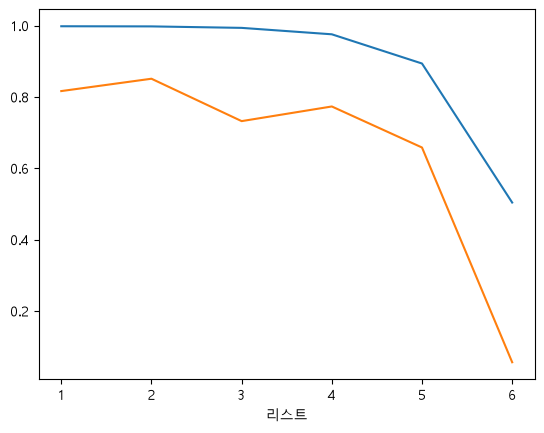

In [233]:
list = [1,2,3,4,5,6]

plt.plot(list,s_list)
plt.plot(list,s2_list)
plt.xlabel('리스트')

In [234]:
# 데이터 학습
ridge =Ridge(alpha=0.01)
ridge.fit(train_scaled,train_label)

# 데이터 예측
predict = ridge.predict(test_scaled)

# 정확도
scor = ridge.score(train_scaled,train_label)
scor2 = ridge.score(test_scaled,test_label)
scor,scor2

(0.9976563542545438, 0.850947706828751)

In [244]:
# 공부시간 4.2 결석 1 공부장소 Cafe
# 예상점수 예측 
# 예상점수 : 00점
# Home - 1.,0.
# Library - 0.,1.
# Cafe - 0.,0.


s = input('공부시간,결석, 공부장소: 예)4.2,1,Cafe')
s = s.split(',')
out = []
out.append(float(s[0]))
out.append(float(s[1]))
if s[2] == 'Home':
    out.append(1.0)
    out.append(0.0)
elif s[2] == 'Library':
    out.append(0.0)
    out.append(1.0)
elif s[2] == 'Cafe':
    out.append(0.0)
    out.append(0.0)

print(out)




[4.2, 1.0, 0.0, 0.0]


In [246]:
result = lr.predict(poly.transform([out]))
print(f'예상점수 : {result[0]:.2f}점')    # → 50.13점

예상점수 : 50.13점


In [249]:
new_scaled = ss.transform(poly.transform([out]))
result = ridge.predict(new_scaled)
print(f'예상점수 : {result[0]:.0f}점')    # → 50점 (49.6)

예상점수 : 50점
